In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import * 
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [2]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torch.optim import Adam

In [3]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using {device}')

Using cpu


In [4]:
import requests
from io import BytesIO
import certifi

In [5]:
# 전처리
path = 'https://bit.ly/ds_boston_csv'
response = requests.get(path,verify=certifi.where(),timeout=15)
response.raise_for_status()
data = pd.read_csv(BytesIO(response.content))

# x, y 분할
target = 'medv'
features = ['lstat', 'ptratio', 'crim']
x = data.loc[:, features]
y= data.loc[:, target]

# xtrain, val 분할
x_train, x_val, y_train, y_val = train_test_split(x, y, test_size=.2, random_state=20)

# 스케일러 선언
scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_val = scaler.transform(x_val)

In [6]:
# 텐서 변환 + Data Loader 생성 함수
def make_DataSet(x_train, x_val, y_train, y_val, batch_size= 32) :
    x_train_tensor = torch.tensor(x_train, dtype= torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype= torch.float32).view(-1,1)
    x_val_tensor = torch.tensor(x_val, dtype= torch.float32)
    y_val_tensor = torch.tensor(y_val, dtype= torch.float32).view(-1,1)
    
    # TensorDataSet 생성
    train_dataset = TensorDataset(x_train_tensor, y_train_tensor)

    # DataLoader 생성
    train_loader = DataLoader(train_dataset, batch_size= batch_size, shuffle=True)
    return train_loader , x_val_tensor, y_val_tensor

In [7]:
# 넘파이 배열변환 - cpu 연산
y_train = y_train.values
y_val = y_val.values

In [8]:
# 데이터 로더 구성 by make_Dataset
train_loader, x_val_ts, y_val_ts = make_DataSet(x_train, x_val, y_train, y_val, 32)

In [9]:
# 모델 구조 설계
n_feature = x.shape[1]
model1= nn.Sequential(nn.Linear(n_feature, 1)).to(device)
loss_fn = nn.MSELoss()
optimizer = Adam(model1.parameters(), lr=0.01)
print(model1)

Sequential(
  (0): Linear(in_features=3, out_features=1, bias=True)
)


In [10]:
# 학습 함수 정의
def train(dataloader, model, loss_fn, optimizer, device):
    size= len(dataloader.dataset)
    num_batches = len(dataloader)
    tr_loss = 0
    model.train()
    for x, y in dataloader:
        x, y = x.to(device), y.to(device)
        pred = model(x)
        loss = loss_fn(pred, y)
        tr_loss += loss
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
    tr_loss /= num_batches
    return tr_loss.item()

In [11]:
# 검증 함수 정의
def evaluate(x_val_tensor, y_val_tensor, model, loss_fn, device):
    model.eval()
    with torch.no_grad():
        x, y = x_val_tensor.to(device), y_val_tensor.to(device)
        pred = model(x)
        val_loss = loss_fn(pred, y).item()
    return val_loss, pred

In [12]:
# 주기 100으로 학습
epochs = 100
tr_loss_list, vals_loss_list = [], [] # list로 저장하는 이유: 학습곡선
for t in range(epochs):
    tr_loss = train(train_loader, model1, loss_fn, optimizer, device)
    val_loss, _ = evaluate(x_val_ts, y_val_ts, model1, loss_fn, device)
    tr_loss_list.append(tr_loss)
    vals_loss_list.append(val_loss)
    print(f'Epoch {t+1}, train loss {tr_loss:4f}, val loss {val_loss:4f}')

Epoch 1, train loss 590.204102, val loss 503.222961
Epoch 2, train loss 569.101501, val loss 493.081726
Epoch 3, train loss 562.998596, val loss 483.113861
Epoch 4, train loss 556.061462, val loss 473.347656
Epoch 5, train loss 545.673706, val loss 463.757568
Epoch 6, train loss 531.818848, val loss 454.322815
Epoch 7, train loss 525.346069, val loss 445.220306
Epoch 8, train loss 514.385193, val loss 436.214966
Epoch 9, train loss 503.679260, val loss 427.389130
Epoch 10, train loss 495.886200, val loss 418.815643
Epoch 11, train loss 487.995880, val loss 410.371826
Epoch 12, train loss 477.729675, val loss 402.015503
Epoch 13, train loss 475.366486, val loss 393.996521
Epoch 14, train loss 467.122864, val loss 386.057129
Epoch 15, train loss 457.633484, val loss 378.307831
Epoch 16, train loss 445.575806, val loss 370.745392
Epoch 17, train loss 441.794647, val loss 363.343597
Epoch 18, train loss 429.859589, val loss 356.060089
Epoch 19, train loss 422.648865, val loss 349.016876
Ep

In [13]:
# 학습 곡선 함수
def dl_learning_curve(tr_loss_list, val_loss_list):
    epochs = list(range(1, len(tr_loss_list)+1))
    plt.plot(epochs, tr_loss_list, label= 'train_err', marker='.')
    plt.plot(epochs, val_loss_list, label= 'val_err', marker='.')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend()
    plt.grid()
    plt.show()

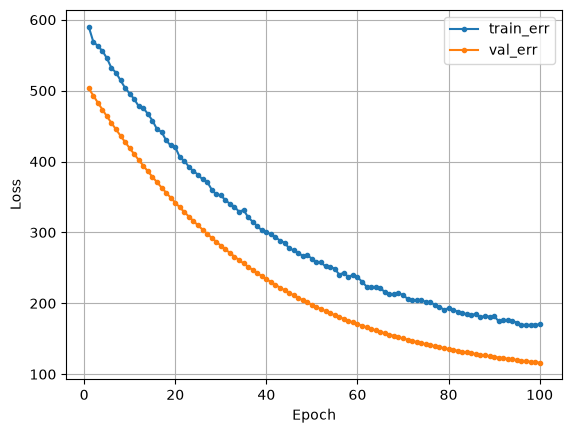

In [14]:
dl_learning_curve(tr_loss_list, vals_loss_list)

In [16]:
_, pred = evaluate(x_val_ts, y_val_ts, model1, loss_fn, device)
mae = mean_absolute_error(y_val_ts.numpy(), pred.numpy())
mape = mean_absolute_percentage_error(y_val_ts.numpy(), pred.numpy())
print('MAE:', mae)
print('MAPE:', mape)

MAE: 7.422201633453369
MAPE: 0.3611881732940674
